In [41]:
import os
try:
    os.chdir("experiments/2021-08-26_multiple-runs-one-param-stratified")
except:
    pass
os.chdir("../..")
os.getcwd()

'/home/joshuab'

In [122]:
import plotnine as pn
import numpy as np
import pandas as pd
from datetime import date, timedelta
from math import ceil
from models import prevalence_model, logPDF_prev, params
from scipy import stats, optimize

In [126]:
start_date = date(2020, 8, 31)
end_date = date(2020, 11, 15)
dates = pd.date_range(start_date, end_date, freq="1D").date
n_days = (end_date - start_date).days + 1
n_weeks = n_days / 7
print("Running for {} days ({} weeks) from {} to {}.".format(n_days, n_weeks, start_date, end_date))
n_matrices = ceil(n_weeks)
matrix_dates = pd.date_range(start_date, end_date-timedelta(days=1), freq="7D")
assert len(matrix_dates) == n_matrices
matrices_list = []
for d in matrix_dates:
    file = "contact_m/2021-08-27/England/{}.csv".format(d.date())
    matrices_list.append(np.loadtxt(file, delimiter=","))
matrices = np.stack(matrices_list)
n_strata = matrices.shape[1]
assert n_strata == 6
model = prevalence_model.SingleRegionStratifiedSEIRCompartmental(matrices, n_days)

Running for 77 days (11.0 weeks) from 2020-08-31 to 2020-11-15.


# Priors

Those based on the literature are explained [in this Google Doc](https://docs.google.com/document/d/1g1GTrjy-Nt109PnGv6KzWA5yyr6rX96VALQlqdmBcJ8/edit#heading=h.w6ov24mi6kp).
The random walk standard deviation parameter is explored further below.

## Susceptibility

Age classes:

In [112]:
pop = pd.read_csv("contact_m/2021-08-27/population.csv")
pop["AgeGroup"]

0     [0,11)
1    [11,16)
2    [16,25)
3    [25,50)
4    [50,70)
5     [70,+)
Name: AgeGroup, dtype: object

In [100]:
susc_ci_by_age = (1 - np.array([
    [1, 10],
    [1, 10],
    [3, 10],
    [5.7, 8.3],
    [2.8, 6.9],
    [2.8, 3.8],
]) / 100)[:,[1,0]]
susc_ci_by_age

array([[0.9  , 0.99 ],
       [0.9  , 0.99 ],
       [0.9  , 0.97 ],
       [0.917, 0.943],
       [0.931, 0.972],
       [0.962, 0.972]])

In [105]:
susc_means = 1 - np.array([0.04, 0.06, 0.08, (7.8+6.1+6.4)/300, (0.5*5.9+3.2+0.5*3.3)/300, 0.033])

In [108]:
def beta_mom(mean, p1, p2):
    var = ((p2-p1)/1.96)**2
    a = (mean*(1-mean)/var-1)*mean
    b = (mean*(1-mean)/var-1)*(1-mean)
    return a, b

# def beta_parameters(p1, p2):
#     "Find parameters for a beta random variable X so that P(X > x1) = p1 and P(X > x2) = p2."
#     x1 = 0.025
#     x2 = 0.975
#     def start():
#         mean = (p1+p2)/2
#         var = ((p2-p1)/1.96)**2
#         a = (mean*(1-mean)/var-1)*mean
#         b = (mean*(1-mean)/var-1)*(1-mean)
#         return a, b

#     def square(x): 
#         return x*x

#     def objective(v):
#         (a, b) = v
#         temp  = square( stats.beta.cdf(x1, a, b) - p1 )
#         temp += square( stats.beta.cdf(x2, a, b) - p2 )
#         return temp
#     return start()
#     # arbitrary initial guess of (3, 3) for parameters
#     xopt = optimize.fmin(objective, start())
#     return (xopt[0], xopt[1])

# susc_beta_params = np.array([beta_parameters(*s) for s in susc_ci_by_age])
# for a, b in susc_beta_params:
#     dist = stats.beta(a=a, b=b)
#     print((a,b))
#     print("Value {} ({} to {})".format(dist.mean(), dist.ppf(0.025), dist.ppf(0.975)))
    
susc_beta_params = np.array([beta_mom(m, *s) for m, s in zip(susc_means, susc_ci_by_age)])
for a, b in susc_beta_params:
    dist = stats.beta(a=a, b=b)
    print("Value {} ({} to {})".format(dist.mean(), dist.ppf(0.025), dist.ppf(0.975)))

Value 0.9600000000000001 (0.8329347355695849 to 0.9997499038548067)
Value 0.94 (0.8233015504582776 to 0.9951879110175842)
Value 0.92 (0.8373817770643062 to 0.974917791125014)
Value 0.9323333333333333 (0.9041383992630931 to 0.95595727723211)
Value 0.974 (0.9200700103944016 to 0.9981461891218334)
Value 0.9669999999999999 (0.9563002839687536 to 0.97625755277543)


In [254]:
i0_beta_params = beta_mom(0.0022*(4/14), 0.001/5, 2*0.0041/5)
a, b = i0_beta_params
dist = stats.beta(a=a, b=b)
print("Value {} ({} to {})".format(dist.mean(), dist.ppf(0.025), dist.ppf(0.975)))

Value 0.0006285714285714285 (4.914050187167561e-06 to 0.0026587058486021394)


In [111]:
susc_betas = [stats.beta(*p) for p in susc_beta_params]

In [331]:
from importlib import reload
reload(params)
reload(logPDF_prev)
# priors = {
#     "dI": params.FixedParam(true_params["dI"]),
#     "dL": params.FixedParam(true_params["dL"]),
#     "pi": params.VectorParam(8, stats.beta(100, 6)),
#     "i0": params.ExpAfterPrior(stats.norm(-7.8, 1.6)),
#     "matrix_modifiers": params.MatrixSusceptibleChildren(params.ExpAfterPrior(stats.norm(-0.69, 0.35)), 8, 3),
#     "psir": params.Param(stats.norm(0.05, 0.01)),
#     "beta": params.LogGaussianRW(stats.expon(scale=1), model.num_betas),
# }
priors = {
    "dL": params.FixedParam(3.5),
    "dI": params.FixedParam(4),
    "pi": params.VectorParamMultiplePriors(n_strata, susc_betas),
    "i0": params.Param(stats.beta(*i0_beta_params)),
    "matrix_modifiers": params.MatrixSusceptibleChildren(params.ExpAfterPrior(stats.norm(-0.69, 0.35)), n_strata, 1),
    "psir": params.Param(stats.norm(0.056/1.086268, 0.003/1.086268)),
    "beta": params.LogGaussianRW(stats.expon(scale=1/17.3), model.num_betas),
}
log_posterior = logPDF_prev.LogPosteriorStratifiedRegion(model, None, None, priors)
num_sims = 500
nni = np.empty((num_sims, n_days, n_strata))
for i in range(num_sims):
    prior_draw = {
        k: v.draw_from_prior() for k, v in priors.items()
    }
    nni[i] = log_posterior.simulate(log_posterior.param_value_dict_to_array(prior_draw))[0]

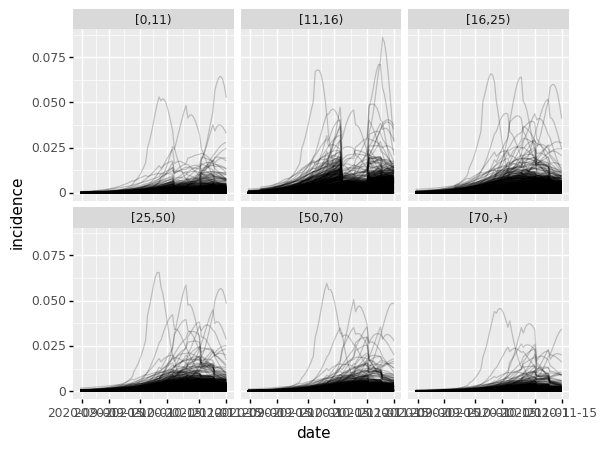

<ggplot: (8750196941807)>

In [344]:
df_sim = pd.DataFrame(nni.flatten(), index=pd.MultiIndex.from_product([range(num_sims), dates, pop["AgeGroup"]],
                                                                      names=["sim", "date", "age"]), columns=["incidence"])\
    .reset_index()
(pn.ggplot(df_sim, pn.aes("date", "incidence", group="sim")) +
 pn.geom_line(alpha=0.2) +
 pn.facet_wrap("age")
)

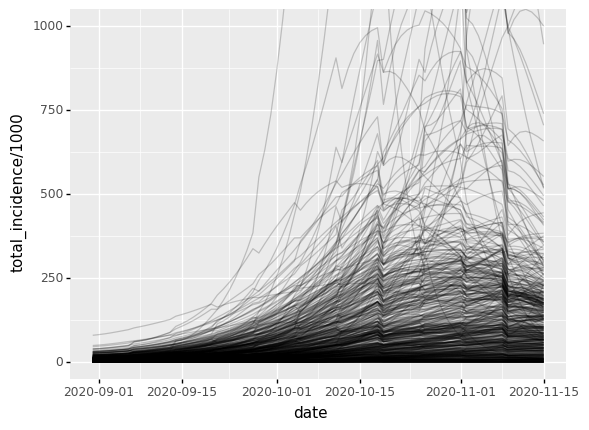

<ggplot: (8750197041935)>

In [345]:
df_total = df_sim.merge(pop, left_on="age", right_on="AgeGroup")\
        .groupby(["sim", "date"])\
        .apply(lambda df: sum(df["population"] * df["incidence"]))\
        .rename("total_incidence")\
        .reset_index()
(pn.ggplot(df_total, pn.aes("date", "total_incidence/1000", group="sim")) +
 pn.geom_line(alpha=0.2) +
 pn.coord_cartesian(ylim=(0,1e3)) 
)

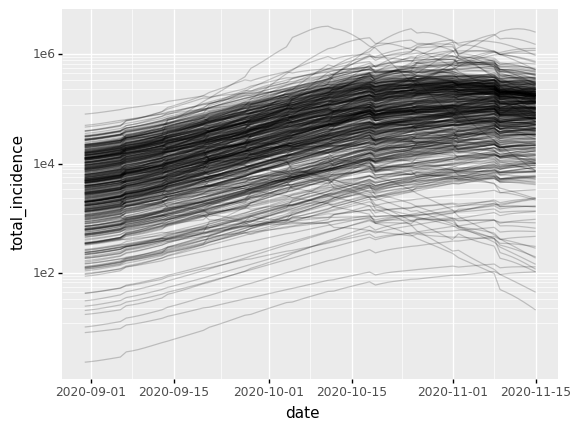

<ggplot: (-9223363286669091149)>

In [346]:
(pn.ggplot(df_total, pn.aes("date", "total_incidence", group="sim")
 ) +
 pn.geom_line(alpha=0.2) +
 pn.scale_y_log10()
)

### First 30 days

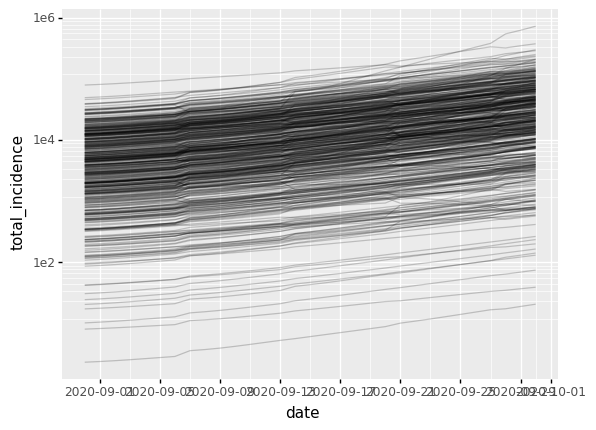

<ggplot: (-9223363286660233191)>

In [347]:
(pn.ggplot(df_total[df_total["date"].dt.date <= dates[30]], pn.aes("date", "total_incidence", group="sim")
 ) +
 pn.geom_line(alpha=0.2) +
 pn.scale_y_log10()
)

Near-straight exponential growth, as expected.
What is the growth rate?

/home/joshuab/COVID/SEIR_prevalence/venv/lib/python3.6/site-packages/plotnine/layer.py:324: PlotnineWarning: stat_density : Removed 13 rows containing non-finite values.


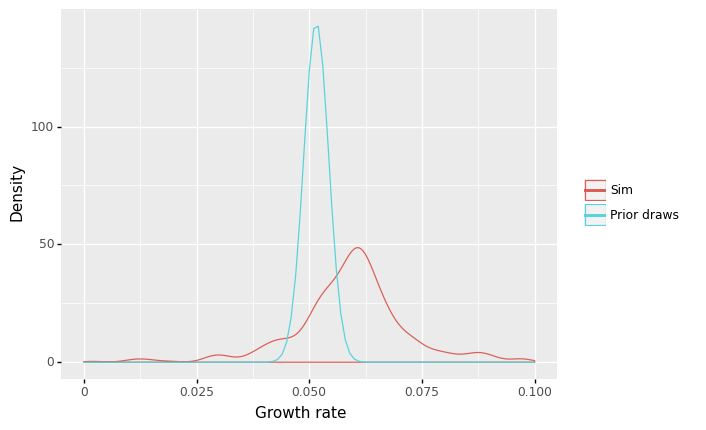

<ggplot: (8750185677039)>

In [349]:
df_day0 = df_total[df_total["date"].dt.date == dates[0]]
df_day30 = df_total[df_total["date"].dt.date == dates[30]]
growth = (np.log(df_day30["total_incidence"].values) - np.log(df_day0["total_incidence"].values))  / 30
(pn.ggplot(df_day0, pn.aes(x=growth)) +
 pn.geom_density(pn.aes(colour="'Sim'")) +
 pn.xlim(0, 0.1) +
 pn.stat_function(pn.aes(colour="'Prior draws'"), fun=priors["psir"]._prior.pdf) +
 pn.labs(x="Growth rate", y="Density", colour="")
)

In [350]:
growth.mean()

0.05906852662912638

In [351]:
np.array([priors["psir"].draw_from_prior() for _ in range(500)]).mean()

0.051477903330592635

In [352]:
0.056/1.086268

0.051552655514108855

In [317]:
matrices.shape

(11, 6, 6)

In [319]:
eigenvals, eigenvecs = np.linalg.eig(matrices)
dominant_eigenvals_pos = np.argmax(abs(eigenvals), axis=1)
for i in enumerate(dominant_eigenvals_pos):
    print(eigenvals[i,pos])

IndexError: index 24 is out of bounds for axis 0 with size 11

In [342]:
eigenvals[:,0]

array([ 8.69179419,  9.89561446, 10.18101766, 10.26766874, 10.48118304,
       10.24779938, 10.14167747,  8.42190389,  8.44451608,  9.07936542,
        8.00534746])

In [330]:
eigenvals[:,0].mean()/eigenvals[0,0]

1.0862689512818722

In [321]:
eigenvals.shape

(11, 6)

In [323]:
np.argmax(abs(eigenvals), axis=1)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [320]:
dominant_eigenval_pos

24

/home/joshuab/COVID/SEIR_prevalence/venv/lib/python3.6/site-packages/plotnine/layer.py:324: PlotnineWarning: stat_density : Removed 11 rows containing non-finite values.


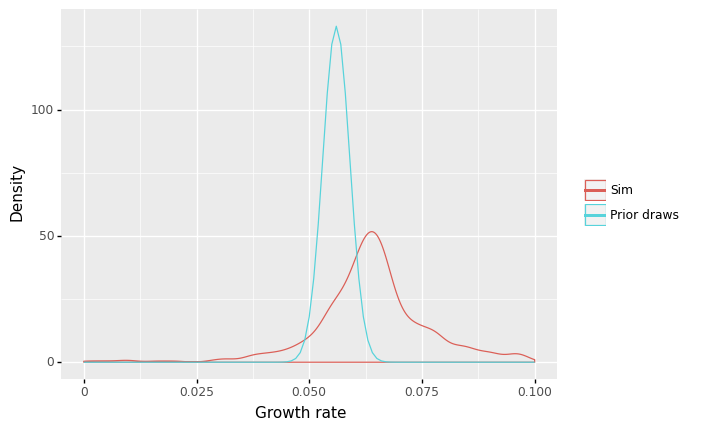

<ggplot: (-9223363286670441237)>

In [315]:
df_day0 = df_total[df_total["date"].dt.date == dates[0]]
df_day30 = df_total[df_total["date"].dt.date == dates[30]]
growth = (np.log(df_day30["total_incidence"].values) - np.log(df_day0["total_incidence"].values))  / 30
(pn.ggplot(df_day0, pn.aes(x=growth)) +
 pn.geom_density(pn.aes(colour="'Sim'")) +
 pn.xlim(0, 0.1) +
 pn.stat_function(pn.aes(colour="'Prior draws'"), fun=priors["psir"]._prior.pdf) +
 pn.labs(x="Growth rate", y="Density", colour="")
)

## Random walk standard deviation

### Candidates

Half-t distributions, in particular half-Cauchy, are often recommended for standard deviation parameters ([Gelman 2006](https://projecteuclid.org/journals/bayesian-analysis/volume-1/issue-3/Prior-distributions-for-variance-parameters-in-hierarchical-models-comment-on/10.1214/06-BA117A.full?tab=ArticleLink); [Polson and Scott 2012](https://projecteuclid.org/journals/bayesian-analysis/volume-7/issue-4/On-the-Half-Cauchy-Prior-for-a-Global-Scale-Parameter/10.1214/12-BA730.full)).
A half-Normal distribution (as the limit of the half-t distribution) and an exponential distribution (as used in the MRC-BSU RTM).
An exponential distribution is the penalised-complexity prior, as recommended by [Simpson et al. 2017](https://projecteuclid.org/journals/statistical-science/volume-32/issue-1/Penalising-Model-Component-Complexity--A-Principled-Practical-Approach-to/10.1214/16-STS576.full).

A feature of the random walk, as opposed to a hierarchical model which the above papers focus on, is that the number of parameters grows linearly with the number of observations.

All examples shown have median 0.04, which corresponds to a random walk with a standard deviation of approximately $\log(0.1)$, and hence the values of $\beta(t)$ changing by around 10% per week.

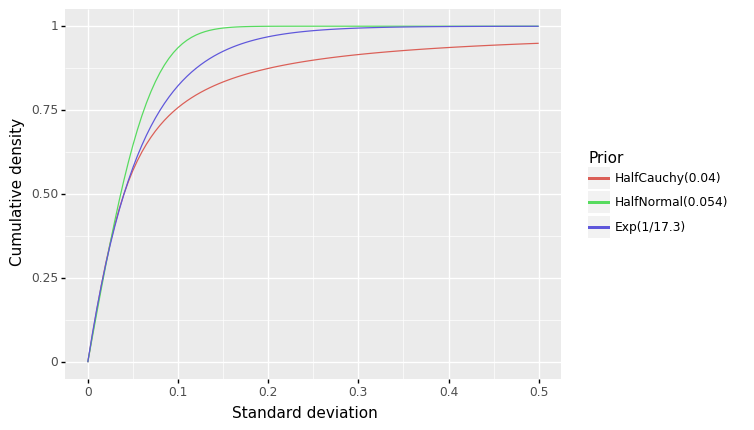

<ggplot: (8750196929081)>

In [16]:
(pn.ggplot(None) +
 pn.stat_function(pn.aes(x=np.linspace(0,.5,100), colour="'HalfCauchy(0.04)'"), fun=stats.halfcauchy.cdf, args={"scale": 0.04}) +
 pn.stat_function(pn.aes(x=np.linspace(0,.5,100), colour="'HalfNormal(0.054)'"), fun=stats.halfnorm.cdf, args={"scale": 0.054}) +
 pn.stat_function(pn.aes(x=np.linspace(0,.5,100), colour="'Exp(1/17.3)'"), fun=stats.expon.cdf, args={"scale": 1/17.3}) +
 pn.labs(x="Standard deviation", y="Cumulative density", colour="Prior")
)

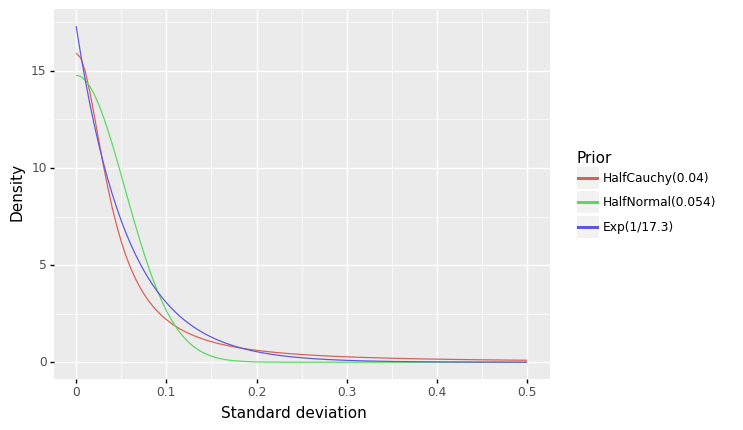

<ggplot: (8750197255351)>

In [14]:
(pn.ggplot(None) +
 pn.stat_function(pn.aes(x=np.linspace(0,.5,100), colour="'HalfCauchy(0.04)'"), fun=stats.halfcauchy.pdf, args={"scale": 0.04}) +
 pn.stat_function(pn.aes(x=np.linspace(0,.5,100), colour="'HalfNormal(0.054)'"), fun=stats.halfnorm.pdf, args={"scale": 0.054}) +
 pn.stat_function(pn.aes(x=np.linspace(0,.5,100), colour="'Exp(1/17.3)'"), fun=stats.expon.pdf, args={"scale": 1/17.3}) +
 pn.labs(x="Standard deviation", y="Density", colour="Prior")
)

/home/joshuab/COVID/SEIR_prevalence/venv/lib/python3.6/site-packages/ipykernel_launcher.py:2: RuntimeWarning: divide by zero encountered in double_scalars
/home/joshuab/COVID/SEIR_prevalence/venv/lib/python3.6/site-packages/ipykernel_launcher.py:3: RuntimeWarning: divide by zero encountered in double_scalars
/home/joshuab/COVID/SEIR_prevalence/venv/lib/python3.6/site-packages/ipykernel_launcher.py:4: RuntimeWarning: divide by zero encountered in double_scalars


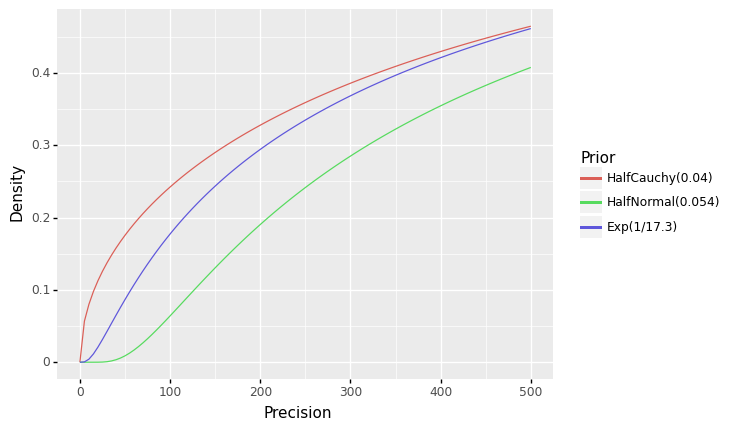

<ggplot: (8750196903951)>

In [19]:
(pn.ggplot(None) +
 pn.stat_function(pn.aes(x=np.linspace(0,500,500), colour="'HalfCauchy(0.04)'"), fun=lambda x: 1-stats.halfcauchy.cdf(1/np.sqrt(x), scale=0.04)) +
 pn.stat_function(pn.aes(x=np.linspace(0,500,500), colour="'HalfNormal(0.054)'"), fun=lambda x: 1-stats.halfnorm.cdf(1/np.sqrt(x), scale=0.054)) +
 pn.stat_function(pn.aes(x=np.linspace(0,500,500), colour="'Exp(1/17.3)'"), fun=lambda x: 1-stats.expon.cdf(1/np.sqrt(x), scale=1/17.3)) +
 pn.labs(x="Precision", y="Density", colour="Prior")
)

In [371]:
# (pn.ggplot(None) +
# # pn.stat_function(pn.aes(x=np.linspace(0,1,500), colour="'HalfCauchy(0.04)'"), fun=lambda x: 2*x**(-3)*stats.halfcauchy.pdf(1/np.sqrt(x), scale=0.04)) +
#  pn.stat_function(pn.aes(x=np.linspace(0,100,500), colour="'HalfNormal(0.054)'"), fun=lambda x: 2*x**(-3)*stats.halfnorm.pdf(1/np.sqrt(x), scale=0.054)) +
#  pn.stat_function(pn.aes(x=np.linspace(0,100,500), colour="'Exp(1/17.3)'"), fun=lambda x: 2*x**(-3)*stats.expon.pdf(1/np.sqrt(x), scale=1/17.3)) +
#  pn.labs(x="Precision", y="Density", colour="Prior")
# )

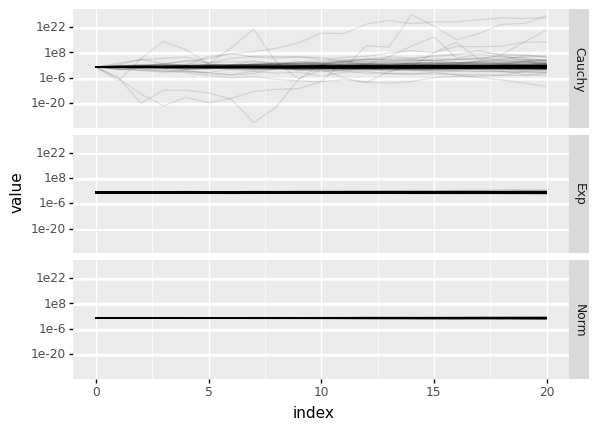

<ggplot: (-9223363286658132245)>

In [372]:
priors = {
    "Cauchy": stats.halfcauchy(scale=0.04),
    "Norm": stats.halfnorm(scale=0.054),
    "Exp": stats.expon(scale=1/17.3)
}

def do_walks(name, sd_prior):
    sd = sd_prior.rvs(1000)
    walk = np.exp(stats.norm(0, sd).rvs((20, sd.shape[0])).cumsum(axis=0))
    df = pd.DataFrame(np.vstack([np.ones(sd.shape[0]), walk])).reset_index().melt(var_name="group", id_vars="index")
    df["prior_name"] = name
    return df

dfs = []
for n, p in priors.items():
    dfs.append(do_walks(n, p))
df = pd.concat(dfs)
(pn.ggplot(df, pn.aes(x="index", y="value", group="group")) +
 pn.geom_line(alpha=0.1) +
 pn.facet_grid("prior_name~") +
 pn.scale_y_log10()
)

In [386]:
df.groupby(["index", "prior_name"]).mean("value").reset_index(1).pivot(columns="prior_name")

value                    
prior_name        Cauchy       Exp      Norm
index                                       
0           1.000000e+00  1.000000  1.000000
1           1.157045e+00  1.003606  1.004099
2           6.097532e+01  1.003785  1.002067
3           1.599830e+11  1.006444  1.002320
4           3.141086e+06  1.011995  1.004985
5           7.212073e+02  1.014220  1.003785
6           3.283994e+07  1.014771  1.002561
7           5.922465e+17  1.023049  1.001952
8           2.085493e+07  1.027223  1.003052
9           2.072553e+10  1.034842  1.003780
10          4.243830e+15  1.038171  1.004852
11          2.517327e+15  1.037916  1.006093
12          3.919072e+20  1.041701  1.007246
13          4.297836e+22  1.044382  1.005044
14          5.589539e+25  1.047285  1.006398
15          7.763955e+21  1.046126  1.008504
16          8.057482e+21  1.055200  1.010120
17          9.318113e+22  1.067826  1.012359
18          1.064535e+24  1.074661  1.011234
19          5.054420e+23  1.107912  1.015630
20          2.031070e+25  1.093762  1.016556

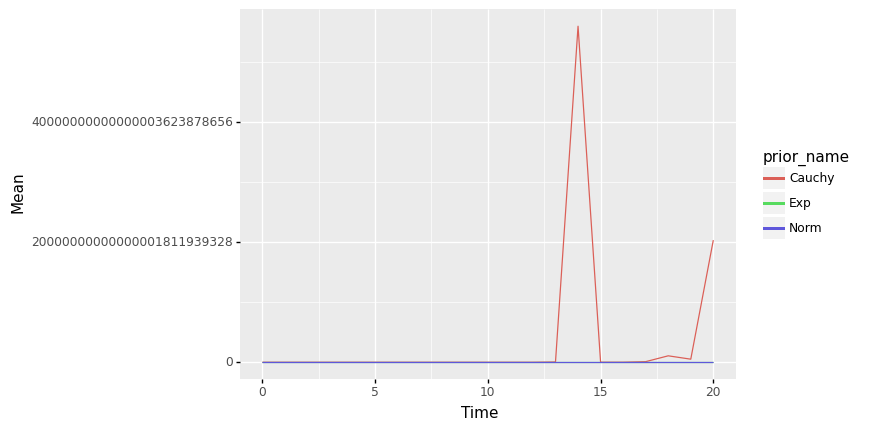

<ggplot: (8750193520637)>

In [373]:
(pn.ggplot(
    df.groupby(["index", "prior_name"]).mean("value").reset_index(),
    pn.aes("index", "value", colour="prior_name")) +
 pn.geom_line() +
 pn.labs(x="Time", y="Mean")
)

/home/joshuab/COVID/SEIR_prevalence/venv/lib/python3.6/site-packages/pandas/core/series.py:726: RuntimeWarning: divide by zero encountered in log10


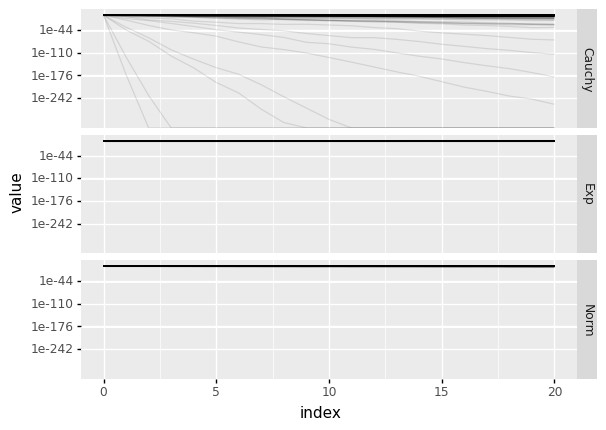

<ggplot: (8750196183132)>

In [388]:
def do_walks2(name, sd_prior):
    sd = sd_prior.rvs(1000)
    walk = np.exp(stats.norm(-sd**2/2, sd).rvs((20, sd.shape[0])).cumsum(axis=0))
    df = pd.DataFrame(np.vstack([np.ones(sd.shape[0]), walk])).reset_index().melt(var_name="group", id_vars="index")
    df["prior_name"] = name
    return df

dfs = []
for n, p in priors.items():
    dfs.append(do_walks2(n, p))
df2 = pd.concat(dfs)
(pn.ggplot(df2, pn.aes(x="index", y="value", group="group")) +
 pn.geom_line(alpha=0.1) +
 pn.facet_grid("prior_name~") +
 pn.scale_y_log10()
)

In [389]:
df2.groupby(["index", "prior_name"]).mean("value").reset_index(1).pivot(columns="prior_name")

value                    
prior_name    Cauchy       Exp      Norm
index                                   
0           1.000000  1.000000  1.000000
1           1.006503  0.996397  0.998792
2           0.991743  0.997536  1.000309
3           0.988510  1.001269  0.999973
4           0.994548  1.000664  0.999870
5           0.996803  0.993765  1.000820
6           0.983971  0.995336  1.000148
7           0.967476  0.994489  1.000059
8           0.963692  0.994395  0.998143
9           0.955234  0.997167  0.997989
10          0.951994  0.998270  0.999386
11          0.953086  0.999212  0.995421
12          0.948559  1.001621  0.996556
13          0.950413  1.000270  0.998710
14          0.942827  1.002455  0.998226
15          0.947240  0.999611  1.000813
16          0.933882  1.008376  0.999447
17          0.932544  1.010974  1.000545
18          0.937597  1.012174  0.999075
19          0.939805  1.014239  0.999857
20          0.932677  1.016558  0.998527

I think the Normal prior looks most reasonable, the other two go off to very high values occaisionally.